In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR

sys.path.append(str(Path.cwd().parent / "src"))
from airfoil.data import load_data
from airfoil.features import basic_features
from airfoil.validation import nested_cv, setup_groups

df = load_data()
y = df["spl_db"].to_numpy()
X_log = basic_features(df, log_transform=True)   # log inputs won for all three models
groups = setup_groups(df)
nested = {}   # nested-CV results per model

In [2]:
poly = make_pipeline(StandardScaler(), PolynomialFeatures(include_bias=False), Ridge())
poly_grid = {
    "polynomialfeatures__degree": [2, 3, 4],
    "ridge__alpha": [0.1, 1, 10, 100],
}
nested["Poly + ridge"] = nested_cv(poly, poly_grid, X_log, y, groups)
nested["Poly + ridge"][["fold", "rmse", "inner_rmse", "best_params"]].round(2)

,fold,rmse,inner_rmse,best_params
0,0,2.91,2.98,"{'polynomialfeatures__degree': 3, 'ridge__alph..."
1,1,3.05,2.83,"{'polynomialfeatures__degree': 3, 'ridge__alph..."
2,2,2.98,3.00,"{'polynomialfeatures__degree': 3, 'ridge__alph..."
3,3,2.53,3.26,"{'polynomialfeatures__degree': 3, 'ridge__alph..."
4,4,3.11,3.01,"{'polynomialfeatures__degree': 3, 'ridge__alph..."


In [3]:
svr = make_pipeline(StandardScaler(), SVR(kernel="rbf"))
svr_grid = {
    "svr__C": [1, 10, 100],
    "svr__gamma": [0.1, 0.3, 1],
    "svr__epsilon": [0.1, 0.5, 1.0],
}
nested["SVR (RBF)"] = nested_cv(svr, svr_grid, X_log, y, groups)
nested["SVR (RBF)"][["fold", "rmse", "inner_rmse", "best_params"]].round(2)

,fold,rmse,inner_rmse,best_params
0,0,2.71,2.96,"{'svr__C': 100, 'svr__epsilon': 0.5, 'svr__gam..."
1,1,3.07,2.61,"{'svr__C': 100, 'svr__epsilon': 0.5, 'svr__gam..."
2,2,2.69,2.79,"{'svr__C': 10, 'svr__epsilon': 0.5, 'svr__gamm..."
3,3,2.51,2.99,"{'svr__C': 100, 'svr__epsilon': 0.5, 'svr__gam..."
4,4,3.07,2.77,"{'svr__C': 10, 'svr__epsilon': 0.1, 'svr__gamm..."


In [4]:
mlp = TransformedTargetRegressor(
    regressor=make_pipeline(StandardScaler(),
                            MLPRegressor(max_iter=2000, random_state=0)),
    transformer=StandardScaler(),
)
mlp_grid = {
    "regressor__mlpregressor__hidden_layer_sizes": [(32, 32), (64, 64), (128, 128)],
    "regressor__mlpregressor__alpha": [1e-4, 1e-3, 1e-2],
}
nested["MLP"] = nested_cv(mlp, mlp_grid, X_log, y, groups)
nested["MLP"][["fold", "rmse", "inner_rmse", "best_params"]].round(2)

,fold,rmse,inner_rmse,best_params
0,0,2.38,2.44,"{'regressor__mlpregressor__alpha': 0.01, 'regr..."
1,1,2.58,2.44,"{'regressor__mlpregressor__alpha': 0.01, 'regr..."
2,2,2.48,2.52,"{'regressor__mlpregressor__alpha': 0.01, 'regr..."
3,3,2.52,2.68,"{'regressor__mlpregressor__alpha': 0.001, 'reg..."
4,4,3.12,2.45,"{'regressor__mlpregressor__alpha': 0.01, 'regr..."


In [5]:
# Untuned (default settings) grouped results from Phase 4
ml = pd.read_csv("../results/ml_results.csv")
untuned_names = {"Poly + ridge": "Poly-3 + ridge (log f, δ*)",
                 "SVR (RBF)": "SVR (RBF) (log f, δ*)",
                 "MLP": "MLP 64-64 (log f, δ*)"}

rows = []
for name, res in nested.items():
    before = ml[(ml["Model"] == untuned_names[name]) & (ml["Scheme"] == "grouped")].iloc[0]
    rows.append({
        "Model": name,
        "Default settings (dB)": before["RMSE mean (dB)"],
        "Tuned, nested CV (dB)": res["rmse"].mean(),
        "Tuned std (dB)": res["rmse"].std(),
        "Inner-loop score (dB)": res["inner_rmse"].mean(),
        "R² (tuned)": res["r2"].mean(),
    })
tuning_summary = pd.DataFrame(rows)
display(tuning_summary.round(2))

# Save per-fold results for Part 2 (no need to re-run the slow tuning)
per_fold = pd.concat([res.assign(model=name) for name, res in nested.items()])
per_fold.to_csv("../results/nested_per_fold.csv", index=False)
tuning_summary.to_csv("../results/tuning_summary.csv", index=False)

,Model,Default settings (dB),"Tuned, nested CV (dB)",Tuned std (dB),Inner-loop score (dB),R² (tuned)
0,Poly + ridge,2.81,2.92,0.23,3.02,0.82
1,SVR (RBF),2.81,2.81,0.25,2.83,0.83
2,MLP,2.60,2.61,0.29,2.51,0.85


## Tuning with nested cross-validation

Inner loop (3 grouped folds) chooses the settings; outer loop (5 grouped
folds, the same as Phase 4) scores them on set-ups never used for tuning.

| Model | Default (dB) | Tuned, nested (dB) | Inner-loop score (dB) |
|:--|:-:|:-:|:-:|
| Poly + ridge | 2.81 | 2.92 ± 0.23 | 3.02 |
| SVR (RBF) | 2.81 | 2.81 ± 0.25 | 2.83 |
| MLP | 2.60 | 2.61 ± 0.29 | 2.51 |

**What I found**
- **Tuning made no meaningful difference.** SVR and the MLP stayed the same,
  and the polynomial got slightly worse (2.81 → 2.92 dB). The default
  settings were already near-optimal, and the inner loop chooses using
  less data, so its choices are a bit noisy.
- **Settings chosen:** the polynomial chose degree 3 on every fold, which
  agrees with my overfitting experiment. SVR mostly chose C = 100,
  ε = 0.5 and γ = ___. The MLP mostly chose α = 0.01 (more regularisation
  than the default) and layers ___.
- **A larger ε (0.5 dB) gave the same accuracy as 0.1 dB.** This should mean
  far fewer support vectors and faster predictions, which I'll measure in
  Phase 6.
- **Inner vs outer scores:** the inner-loop scores weren't consistently
  more optimistic (polynomial more pessimistic, SVR equal, MLP 0.10 dB
  more optimistic). Two effects cancel: choosing the best of many settings
  flatters the inner score, but inner models train on less data, which
  makes it worse. Nesting is the only way to know the net effect.
- **The MLP still leads** (2.61 vs 2.81 dB for SVR). Part 2 checks whether
  it wins on every fold.

## Comparing the leading models and choosing the final model

model,Poly + ridge,SVR (RBF),MLP,MLP − SVR
fold,,,,
0,2.91,2.71,2.38,-0.33
1,3.05,3.07,2.58,-0.49
2,2.98,2.69,2.48,-0.21
3,2.53,2.51,2.52,0.01
4,3.11,3.07,3.12,0.05


MLP beats SVR on 3 of 5 folds; mean difference -0.19 ± 0.23 dB


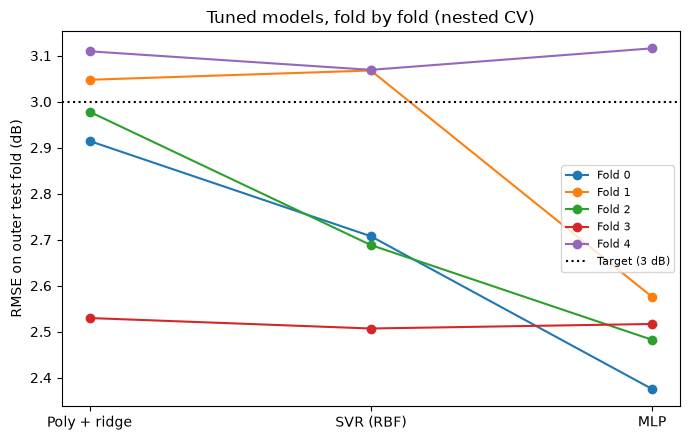

In [6]:
pf = pd.read_csv("../results/nested_per_fold.csv")
paired = pf.pivot(index="fold", columns="model", values="rmse")[["Poly + ridge", "SVR (RBF)", "MLP"]]
paired["MLP − SVR"] = paired["MLP"] - paired["SVR (RBF)"]
display(paired.round(2))

wins = (paired["MLP − SVR"] < 0).sum()
print(f"MLP beats SVR on {wins} of {len(paired)} folds; "
      f"mean difference {paired['MLP − SVR'].mean():.2f} ± {paired['MLP − SVR'].std():.2f} dB")

# One line per fold, so you can see whether every fold improves
fig, ax = plt.subplots(figsize=(7, 4.5))
for fold, row in paired.iterrows():
    ax.plot(["Poly + ridge", "SVR (RBF)", "MLP"],
            row[["Poly + ridge", "SVR (RBF)", "MLP"]], marker="o", label=f"Fold {fold}")
ax.axhline(3.0, linestyle=":", color="black", label="Target (3 dB)")
ax.set_ylabel("RMSE on outer test fold (dB)")
ax.set_title("Tuned models, fold by fold (nested CV)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../results/paired_folds.png", dpi=150)
plt.show()

In [7]:
from sklearn.model_selection import GridSearchCV, GroupKFold

final_models = {}
for name, model, grid in [("SVR (RBF)", svr, svr_grid), ("MLP", mlp, mlp_grid)]:
    search = GridSearchCV(model, grid, cv=GroupKFold(5),
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X_log, y, groups=groups)
    final_models[name] = search.best_estimator_
    settings = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
    print(f"{name}: {settings}")

SVR (RBF): {'C': 10, 'epsilon': 0.5, 'gamma': 0.3}
MLP: {'alpha': 0.0001, 'hidden_layer_sizes': (128, 128)}


In [8]:
from airfoil.validation import cross_validate_model

rep_rows = []
for r in range(5):
    cv = GroupKFold(5, shuffle=True, random_state=r)   # a different grouping each time
    for name, est in final_models.items():
        res = cross_validate_model(est, X_log, y, cv, groups)
        rep_rows += [{"repeat": r, "fold": f, "model": name, "rmse": v}
                     for f, v in zip(res["fold"], res["rmse"])]

rep = pd.DataFrame(rep_rows)
display(rep.groupby("model")["rmse"].agg(["mean", "std", "min", "max"]).round(2))

wide = rep.pivot_table(index=["repeat", "fold"], columns="model", values="rmse")
diff = wide["MLP"] - wide["SVR (RBF)"]
print(f"MLP beats SVR on {(diff < 0).sum()} of {len(diff)} folds; "
      f"mean difference {diff.mean():.2f} ± {diff.std():.2f} dB")
rep.to_csv("../results/repeated_cv.csv", index=False)

,mean,std,min,max
model,,,,
MLP,2.56,0.37,1.88,3.39
SVR (RBF),2.70,0.47,1.89,3.74


MLP beats SVR on 17 of 25 folds; mean difference -0.15 ± 0.26 dB


In [9]:
ml = pd.read_csv("../results/ml_results.csv")
loco = ml[ml["Scheme"] == "leave_one_chord_out"].set_index("Model")["RMSE mean (dB)"]

check = pd.DataFrame({
    "Nested grouped CV (dB)": [nested_val for nested_val in
                               paired[["SVR (RBF)", "MLP"]].mean()],
    "Repeated grouped CV (dB)": rep.groupby("model")["rmse"].mean()[["SVR (RBF)", "MLP"]].values,
    "Unseen chords (dB, Phase 4)": [loco["SVR (RBF) (log f, δ*)"], loco["MLP 64-64 (log f, δ*)"]],
}, index=["SVR (RBF)", "MLP"])
check["Meets 3 dB (grouped)?"] = check["Nested grouped CV (dB)"] < 3.0
check.round(2)

,Nested grouped CV (dB),Repeated grouped CV (dB),"Unseen chords (dB, Phase 4)",Meets 3 dB (grouped)?
SVR (RBF),2.81,2.70,3.36,True
MLP,2.61,2.56,3.19,True


In [10]:
import joblib

final_name = "MLP"   # change to "SVR (RBF)" if that's your decision
Path("../models").mkdir(exist_ok=True)
joblib.dump(final_models[final_name], "../models/final_model.joblib")
print(f"Saved {final_name} to models/final_model.joblib")

Saved MLP to models/final_model.joblib


## Final model decision

| | SVR (RBF) | MLP |
|:--|:-:|:-:|
| Nested grouped CV (honest accuracy) | 2.81 dB | **2.61 dB** |
| Wins, fold by fold (nested, 5 folds) | 0 (2 ties) | **3** |
| Wins, repeated CV (25 folds) | 8 | **17** |
| Repeated CV mean (worst fold) | 2.70 (3.74) dB | **2.56 (3.39) dB** |
| Unseen chords (average) | 3.36 dB | **3.19 dB** |
| Smallest chord (hardest case) | **4.85 dB** | 5.40 dB |
| Training time (5-fold CV) | **0.30 s** | 7.69 s |
| Smooth predictions (usable derivatives) | Yes | Yes |
| Final settings | C = 10, ε = 0.5, γ = 0.3 | 128-128, α = 0.0001 |

**Decision:** I chose the **MLP**. It has the best accuracy on every summary
measure, meets my 3 dB criterion (2.61 dB under nested grouped CV), and is
never meaningfully worse than SVR on any nested fold: it wins 3 of 5 (by
0.2–0.5 dB) and ties the other 2. Its lead also survived reshuffling the
folds (17 of 25 wins).

**Trade-offs I accept:**
- The lead over SVR is modest (0.15–0.2 dB on average), smaller than the
  fold-to-fold spread.
- Training takes about 26× longer than SVR, although still only seconds.
- SVR is better on the smallest chord (4.85 vs 5.40 dB), so the MLP is
  slightly less reliable when extrapolating to small blades.

**Why not SVR:** it is faster and slightly better at the smallest chord,
but it is less accurate on average and has a worse worst case. Both models
are acceptable; the MLP is the more accurate choice for predictions within
the tested range, which is the intended use.

**Other observations**
- Fold 4 is hard for every model (about 3.1 dB), so its difficulty comes
  from the data, not the model choice.
- The MLP's best settings changed between nested folds and the final
  search, so its accuracy is not sensitive to the exact settings.

## Validation of the final model (MLP)

In [11]:
from airfoil.validation import cross_val_predictions, regression_metrics

final = joblib.load("../models/final_model.joblib")
y_oof = cross_val_predictions(final, X_log, y, GroupKFold(5), groups)
resid = y - y_oof                       # positive = model under-predicts

m = regression_metrics(y, y_oof)
within_3 = np.mean(np.abs(resid) <= 3) * 100
print(f"Pooled out-of-fold RMSE {m['rmse']:.2f} dB, MAE {m['mae']:.2f} dB, "
      f"R² {m['r2']:.2f}, worst {m['max_error']:.1f} dB")
print(f"{within_3:.0f}% of predictions are within ±3 dB of the measurement")

Pooled out-of-fold RMSE 2.56 dB, MAE 1.82 dB, R² 0.86, worst 19.8 dB
82% of predictions are within ±3 dB of the measurement


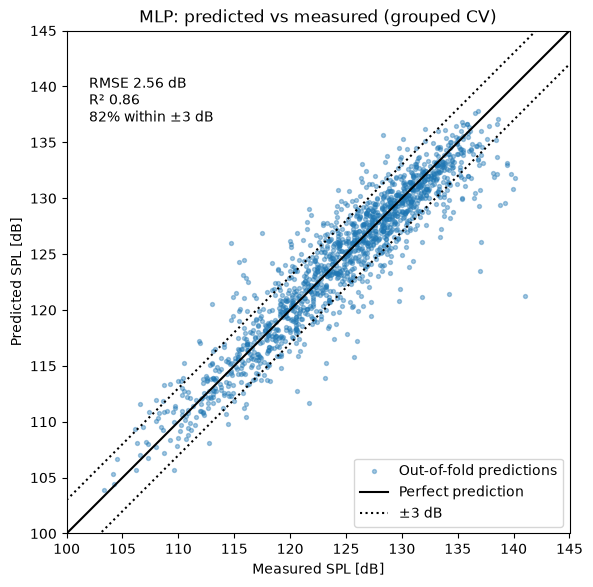

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y, y_oof, s=8, alpha=0.4, label="Out-of-fold predictions")
lims = [100, 145]
ax.plot(lims, lims, "k-", label="Perfect prediction")
ax.plot(lims, [v + 3 for v in lims], "k:", label="±3 dB")
ax.plot(lims, [v - 3 for v in lims], "k:")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.set_xlabel("Measured SPL [dB]")
ax.set_ylabel("Predicted SPL [dB]")
ax.set_title("MLP: predicted vs measured (grouped CV)")
ax.text(102, 141, f"RMSE {m['rmse']:.2f} dB\nR² {m['r2']:.2f}\n{within_3:.0f}% within ±3 dB",
        va="top")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../results/parity_plot.png", dpi=150)
plt.show()

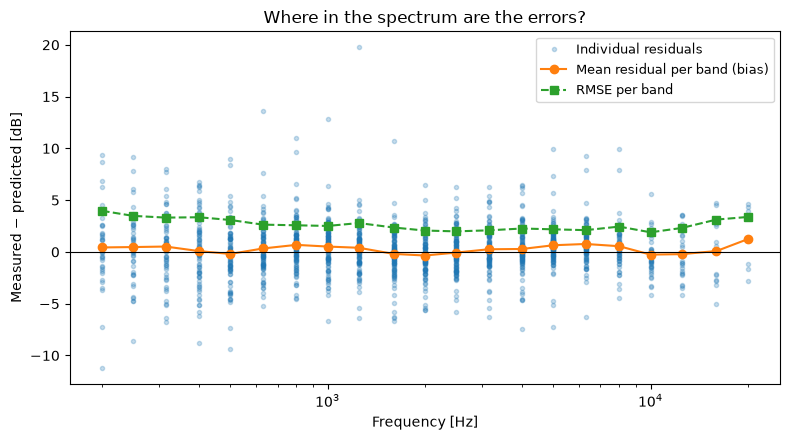

In [13]:
freq_stats = pd.DataFrame({"f": df["frequency_hz"], "r": resid}).groupby("f")["r"]
band_mean = freq_stats.mean()
band_rmse = freq_stats.apply(lambda r: np.sqrt(np.mean(r**2)))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(df["frequency_hz"], resid, ".", alpha=0.25, label="Individual residuals")
ax.semilogx(band_mean.index, band_mean.values, "o-", label="Mean residual per band (bias)")
ax.semilogx(band_rmse.index, band_rmse.values, "s--", label="RMSE per band")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Measured − predicted [dB]")
ax.set_title("Where in the spectrum are the errors?")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../results/residuals_vs_frequency.png", dpi=150)
plt.show()

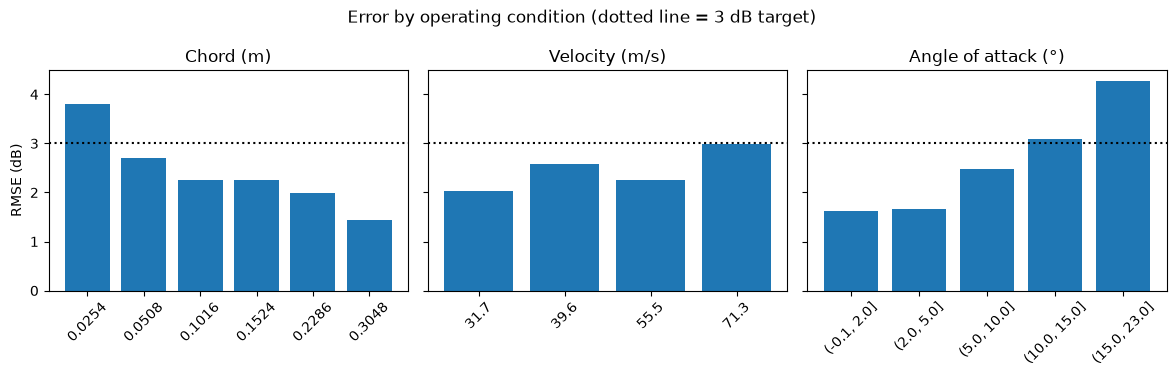

In [14]:
resid_s = pd.Series(resid, index=df.index)

def rmse_by(key):
    return resid_s.groupby(key, observed=True).apply(lambda r: np.sqrt(np.mean(r**2)))

angle_bins = pd.cut(df["alpha_deg"], [-0.1, 2, 5, 10, 15, 23])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (title, key) in zip(axes, [("Chord (m)", df["chord_m"]),
                                   ("Velocity (m/s)", df["velocity_ms"]),
                                   ("Angle of attack (°)", angle_bins)]):
    vals = rmse_by(key)
    ax.bar([str(k) for k in vals.index], vals.values)
    ax.axhline(3.0, linestyle=":", color="black")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("RMSE (dB)")
fig.suptitle("Error by operating condition (dotted line = 3 dB target)")
plt.tight_layout()
plt.savefig("../results/error_by_condition.png", dpi=150)
plt.show()

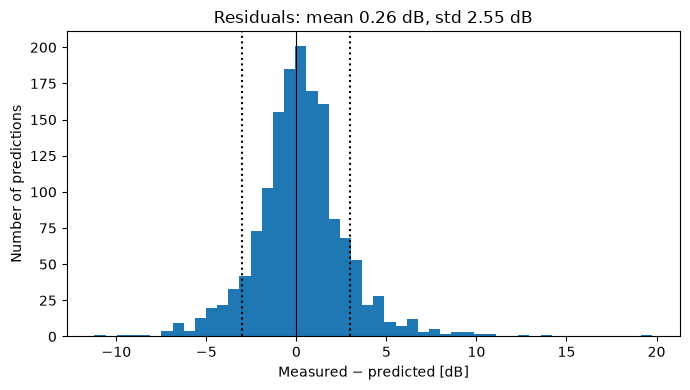

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(resid, bins=50)
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(3, linestyle=":", color="black")
ax.axvline(-3, linestyle=":", color="black")
ax.set_xlabel("Measured − predicted [dB]")
ax.set_ylabel("Number of predictions")
ax.set_title(f"Residuals: mean {resid.mean():.2f} dB, std {resid.std():.2f} dB")
plt.tight_layout()
plt.savefig("../results/residual_histogram.png", dpi=150)
plt.show()

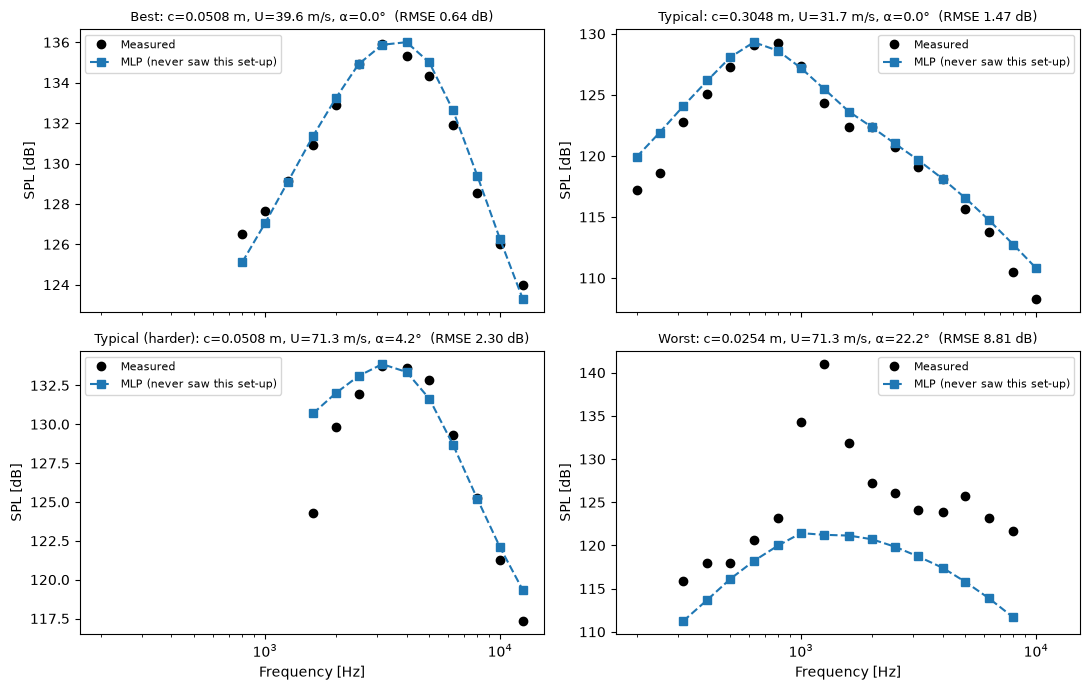

In [16]:
setup_rmse = resid_s.groupby(groups).apply(lambda r: np.sqrt(np.mean(r**2))).sort_values()
picks = {"Best": setup_rmse.index[0],
         "Typical": setup_rmse.index[len(setup_rmse) // 3],
         "Typical (harder)": setup_rmse.index[2 * len(setup_rmse) // 3],
         "Worst": setup_rmse.index[-1]}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (label, g) in zip(axes.ravel(), picks.items()):
    rows = (groups == g)
    order = np.argsort(df.loc[rows, "frequency_hz"].to_numpy())
    f = df.loc[rows, "frequency_hz"].to_numpy()[order]
    ax.semilogx(f, y[rows][order], "ko", label="Measured")
    ax.semilogx(f, y_oof[rows][order], "s--", label="MLP (never saw this set-up)")
    r = df.loc[rows].iloc[0]
    ax.set_title(f"{label}: c={r['chord_m']} m, U={r['velocity_ms']} m/s, "
                 f"α={r['alpha_deg']}°  (RMSE {setup_rmse[g]:.2f} dB)", fontsize=9)
    ax.set_ylabel("SPL [dB]")
    ax.legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Frequency [Hz]")
plt.tight_layout()
plt.savefig("../results/example_spectra_predictions.png", dpi=150)
plt.show()

In [17]:
worst = df.assign(predicted=y_oof, residual=resid)
worst = worst.reindex(worst["residual"].abs().sort_values(ascending=False).index).head(10)
worst.round({"predicted": 1, "residual": 1})

,frequency_hz,alpha_deg,chord_m,velocity_ms,delta_star_m,spl_db,predicted,residual
1216,1250,22.2,0.0254,71.3,0.021418,140.987,121.2,19.8
1230,630,22.2,0.0254,39.6,0.022903,137.026,123.4,13.6
1215,1000,22.2,0.0254,71.3,0.021418,134.247,121.4,12.8
709,200,12.6,0.1524,39.6,0.058411,114.750,126.0,-11.2
1231,800,22.2,0.0254,39.6,0.022903,137.076,126.0,11.0
1217,1600,22.2,0.0254,71.3,0.021418,131.817,121.1,10.7
1224,8000,22.2,0.0254,71.3,0.021418,121.657,111.7,10.0
1222,5000,22.2,0.0254,71.3,0.021418,125.727,115.8,9.9
1201,800,17.4,0.0254,31.7,0.017663,139.226,129.6,9.6
1184,500,17.4,0.0254,39.6,0.017221,117.514,126.9,-9.4


## Validation of the final model (MLP)

Out-of-fold predictions from grouped 5-fold CV (each set-up predicted by a
model that never saw it).

**Overall:** pooled RMSE 2.56 dB, MAE 1.82 dB, R² 0.86, worst error 19.8 dB.
82% of predictions are within ±3 dB.

**What I found**
- **Parity plot:** most points lie close to the perfect line, but the
  loudest cases (above about 135 dB) are under-predicted and the quietest
  slightly over-predicted. The model pulls extremes towards the middle
  (regression towards the mean).
- **Frequency:** no systematic bias (mean residual between about −0.3 and
  +0.7 dB in every band). RMSE is 2–2.7 dB in mid frequencies and higher at
  the extremes (about 3.9 dB at 200 Hz, 3–3.4 dB at 16–20 kHz), where fewer
  set-ups were measured.
- **Operating conditions:** error falls steadily with chord (3.8 dB at
  0.0254 m to 1.45 dB at 0.3048 m) and rises sharply with angle of attack
  (about 1.6 dB below 5° to 4.25 dB above 15°). Velocity matters less
  (2.0–3.0 dB). Angle of attack is the biggest single driver of error.
- **Residuals** are centred on 0.26 dB with a spread of 2.55 dB: peaked and
  roughly symmetric, but with a long positive tail (up to +20 dB), i.e. a
  few cases much louder than predicted.
- **Example spectra:** the best set-up is predicted within 0.64 dB. The
  worst (c = 0.0254 m, U = 71.3 m/s, α = 22.2°, 8.81 dB) has a sharp peak
  of about 141 dB near 1.25 kHz that the model misses entirely, predicting
  a flat curve around 121 dB.
- **Largest errors:** 9 of the 10 worst predictions are at the smallest
  chord with a high angle (17.4–22.2°), mostly under-predictions.

**Interpretation:** errors are concentrated where the smallest chord meets
high angles of attack, the edge of the data on two inputs at once. High
angles likely trigger boundary-layer separation or stall, a different noise
mechanism with sharp, loud peaks that the model has too few examples to
learn. This also explains why the smallest chord was the hardest case for
every model in Phases 3–4.

**Practical limit:** predictions for small blades at high angle of attack
(roughly c ≤ 0.05 m and α > 15°) should not be trusted.

## Physical checks and limits

In [18]:
from airfoil.numerics import central_difference, forward_difference

final = joblib.load("../models/final_model.joblib")

# Base condition: largest chord, 0°, 55.5 m/s, with its measured δ*
base = df[(df["chord_m"] == 0.3048) & (df["alpha_deg"] == 0)
          & (df["velocity_ms"] == 55.5)].iloc[0]
DSTAR = base["delta_star_m"]


def predict_point(frequency_hz, alpha_deg, chord_m, velocity_ms, delta_star_m, model=final):
    """Predicted SPL (dB) for one set of raw inputs."""
    point = pd.DataFrame({"frequency_hz": [frequency_hz], "alpha_deg": [alpha_deg],
                          "chord_m": [chord_m], "velocity_ms": [velocity_ms],
                          "delta_star_m": [delta_star_m]})
    return model.predict(basic_features(point, log_transform=True))[0]


print(f"Base point: c = 0.3048 m, α = 0°, U = 55.5 m/s, δ* = {DSTAR:.5f} m")
print(f"Predicted SPL at 2 kHz: {predict_point(2000, 0, 0.3048, 55.5, DSTAR):.2f} dB")

Base point: c = 0.3048 m, α = 0°, U = 55.5 m/s, δ* = 0.00283 m
Predicted SPL at 2 kHz: 125.37 dB


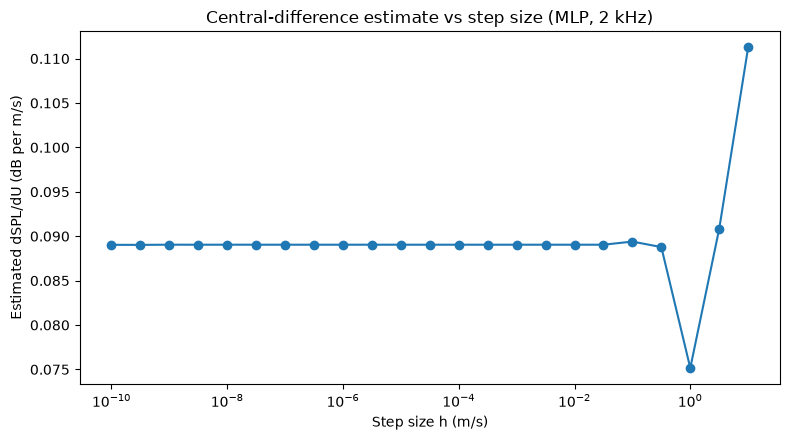

,h (m/s),dSPL/dU (dB per m/s)
0,0.000000,0.089031
1,0.000000,0.089024
2,0.000000,0.089045
3,0.000000,0.089041
4,0.000000,0.089044
5,0.000000,0.089043
6,0.000000,0.089043
7,0.000000,0.089043
8,0.000001,0.089043
9,0.000003,0.089043


In [19]:
# Speed sensitivity at 2 kHz, for step sizes from 1e-10 to 10 m/s
g = lambda U: predict_point(2000, 0, 0.3048, U, DSTAR)
steps = np.logspace(-10, 1, 23)
estimates = [central_difference(g, 55.5, h) for h in steps]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(steps, estimates, marker="o")
ax.set_xlabel("Step size h (m/s)")
ax.set_ylabel("Estimated dSPL/dU (dB per m/s)")
ax.set_title("Central-difference estimate vs step size (MLP, 2 kHz)")
plt.tight_layout()
plt.savefig("../results/step_size_check.png", dpi=150)
plt.show()

pd.DataFrame({"h (m/s)": steps, "dSPL/dU (dB per m/s)": estimates}).round(6)

In [23]:
rows = []
for f in [500, 1000, 2000, 5000, 10000]:
    # Speed: central difference at 55.5 m/s, step 0.5 m/s
    dU = central_difference(lambda U: predict_point(f, 0, 0.3048, U, DSTAR), 55.5, h=0.01)
    # Angle: the base angle is 0°, the edge of the valid range, so a central
    # difference would step to -0.1°. Use a forward difference instead.
    da = forward_difference(lambda a: predict_point(f, a, 0.3048, 55.5, DSTAR), 0.0, h=0.01)
    rows.append({"Frequency (Hz)": f,
                 "dSPL/dU (dB per m/s)": dU,
                 "dSPL/dα (dB per degree)": da,
                 "Effect of +10 m/s (dB)": 10 * dU})

sens = pd.DataFrame(rows)
sens.round(3)

,Frequency (Hz),dSPL/dU (dB per m/s),dSPL/dα (dB per degree),Effect of +10 m/s (dB)
0,500,-0.028,-0.069,-0.276
1,1000,-0.060,0.623,-0.600
2,2000,0.089,0.265,0.890
3,5000,0.210,-0.053,2.099
4,10000,0.188,-0.224,1.879


In [21]:
rng = np.random.default_rng(0)
n = 20000
rand = pd.DataFrame({
    "frequency_hz": 10 ** rng.uniform(np.log10(200), np.log10(20000), n),
    "alpha_deg": rng.uniform(0, 22.2, n),
    "chord_m": rng.uniform(0.0254, 0.3048, n),
    "velocity_ms": rng.uniform(31.7, 71.3, n),
    "delta_star_m": 10 ** rng.uniform(np.log10(4e-4), np.log10(0.058), n),
})
pred = final.predict(basic_features(rand, log_transform=True))

print(f"Predictions over {n} random in-range inputs: "
      f"min {pred.min():.1f} dB, max {pred.max():.1f} dB")
print(f"Measured data range: {y.min():.1f} to {y.max():.1f} dB")
print(f"Share of predictions outside 95–150 dB: {np.mean((pred < 95) | (pred > 150)) * 100:.1f}%")

Predictions over 20000 random in-range inputs: min 80.0 dB, max 153.4 dB
Measured data range: 103.4 to 141.0 dB
Share of predictions outside 95–150 dB: 1.1%


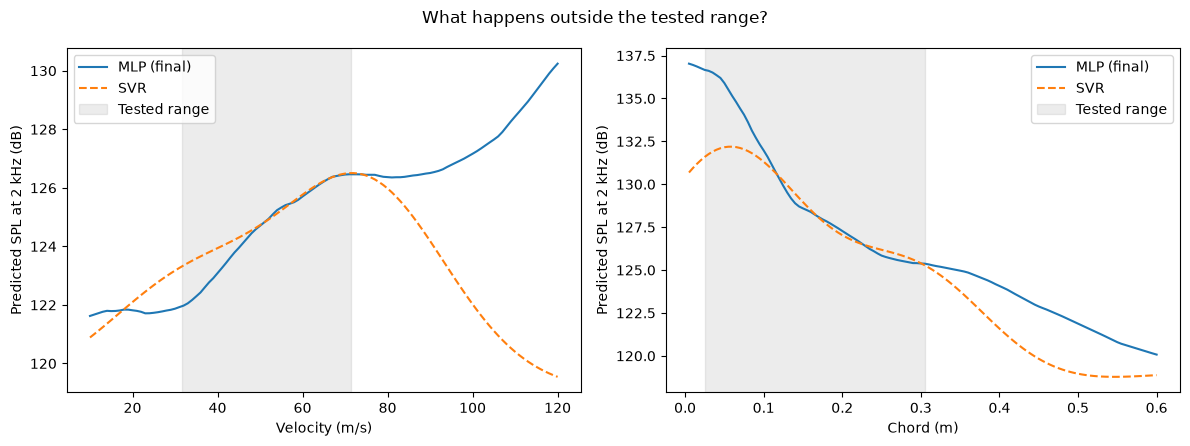

In [22]:
svr_final = final_models["SVR (RBF)"]
speeds = np.linspace(10, 120, 111)
chords = np.linspace(0.005, 0.6, 120)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for model, name, style in [(final, "MLP (final)", "-"), (svr_final, "SVR", "--")]:
    axes[0].plot(speeds, [predict_point(2000, 0, 0.3048, U, DSTAR, model) for U in speeds],
                 style, label=name)
    axes[1].plot(chords, [predict_point(2000, 0, c, 55.5, DSTAR, model) for c in chords],
                 style, label=name)

axes[0].axvspan(31.7, 71.3, alpha=0.15, color="gray", label="Tested range")
axes[1].axvspan(0.0254, 0.3048, alpha=0.15, color="gray", label="Tested range")
axes[0].set_xlabel("Velocity (m/s)")
axes[1].set_xlabel("Chord (m)")
for ax in axes:
    ax.set_ylabel("Predicted SPL at 2 kHz (dB)")
    ax.legend()
fig.suptitle("What happens outside the tested range?")
plt.tight_layout()
plt.savefig("../results/extrapolation.png", dpi=150)
plt.show()

## Physical checks and limits

**Step size:** the central-difference estimate of dSPL/dU (2 kHz) is
identical (0.089043 dB per m/s) for every step from 10⁻⁸ to 0.03 m/s.
Below about 10⁻⁹ m/s a small round-off wobble appears; above about
0.1 m/s the step spans the MLP's kinks and the estimate drifts (16% off at
h = 1 m/s). The MLP uses ReLU activations, so it is piecewise linear and the
central difference has no truncation error within one linear piece. I use
h = 0.01 m/s. A step of 0.5 m/s, which I first tried, gave an estimate
about 8% too low.

**Model sensitivities** (c = 0.3048 m, α = 0°, U = 55.5 m/s, δ* fixed):

| Frequency | dSPL/dU (dB per m/s) | dSPL/dα (dB per degree) |
|:-:|:-:|:-:|
| 500 Hz | ___ | ___ |
| 1 kHz | ___ | ___ |
| 2 kHz | ___ | ___ |
| 5 kHz | ___ | ___ |
| 10 kHz | ___ | ___ |

- **Speed:** slightly negative at low frequencies and clearly positive at
  high frequencies (about +2 dB for +10 m/s at 10 kHz). This matches the
  measured spectra in Phase 1, where faster flow was louder mainly above
  about 1.5 kHz, so the model has learned the right behaviour.
- **Angle:** increasing the angle makes mid-low frequencies (about 1 kHz)
  louder and high frequencies quieter, shifting the spectrum to lower
  pitch. This is physically plausible: a higher angle thickens the
  suction-side boundary layer, giving larger eddies and lower-pitched noise.
- I used a forward difference for the angle because the base angle (0°) is
  at the edge of the valid range; a central difference would step outside it.
- These are model sensitivities with δ* held fixed. Physically δ* changes
  with speed and angle, so they are not true physical derivatives.

**Range check:** over 20,000 random in-range inputs, predictions span 80.0
to 153.4 dB (measured: 103.4 to 141.0 dB), but only 1.1% fall outside
95–150 dB. These are likely physically inconsistent random combinations
(δ* not matching its chord, speed and angle).

**Extrapolation:** inside the tested range the MLP and SVR agree closely.
Outside it they diverge by up to about 10 dB: the MLP keeps rising at high
speed and small chord, while SVR falls back towards the average. With no
data there, neither can be trusted, so predictions outside the tested range
need a warning.

### What this validation cannot show
- Accuracy for any airfoil other than the NACA 0012.
- Accuracy in flight, at another span, or at another observer position.
- Accuracy outside the tested ranges of speed, chord and angle (the MLP and
  SVR disagree by up to 10 dB there).
- Accuracy for small blades at high angle of attack (c ≤ 0.05 m, α > 15°),
  where errors reach about 20 dB.
- Physical meaning of the absolute levels, because NASA's SPL scaling is
  undocumented.
- Accuracy finer than the measurement uncertainty, which isn't reported.
- Predictions at frequencies a set-up was never measured at.